# Dataset Exploration — Fashion-MNIST

## 1. Tujuan Eksplorasi

Notebook ini digunakan untuk memahami karakteristik dataset Fashion-MNIST
sebelum dilakukan tahap data preprocessing dan implementasi model Vision
Transformer (ViT) Minimalis.

Dataset terdiri dari dua file CSV:

- `fashion-mnist_train.csv`
- `fashion-mnist_test.csv`

Eksplorasi dilakukan untuk mengetahui:

1. Struktur dan dimensi dataset.
2. Nama dan tipe data setiap kolom.
3. Missing values dan data duplikat.
4. Distribusi label pada data train dan test.
5. Kesesuaian jumlah fitur piksel dengan ukuran gambar 28 × 28.
6. Rentang nilai piksel.
7. Representasi data CSV menjadi gambar grayscale.

## 2. Batasan Eksplorasi

Notebook ini hanya melakukan pemeriksaan dan visualisasi data.

Tidak dilakukan:
- Normalisasi data.
- Data augmentation.
- Pembagian train-validation.
- Perubahan atau penimpaan dataset asli.
- Training model.

Hasil eksplorasi akan digunakan sebagai dasar pengambilan keputusan
pada tahap Data Preprocessing.

In [1]:
# Import library untuk eksplorasi dataset

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pengaturan tampilan pandas
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)
pd.set_option("display.width", 120)

# Pengaturan visualisasi
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"

print("Library berhasil di-import.")

Library berhasil di-import.


## 3. Membaca Dataset

Pada bagian ini, file CSV train dan test dibaca menggunakan pandas.

Lokasi dataset berada di folder `data/raw/`, sedangkan notebook berada
di folder `notebooks/`.

Kode akan mencoba menemukan folder proyek dari lokasi kerja notebook.
Jika file tidak ditemukan, proses akan dihentikan dengan pesan yang jelas.

Dataset hanya dibaca dan tidak dimodifikasi.

In [2]:
# Menentukan lokasi folder proyek

current_dir = Path.cwd()

# Kandidat lokasi folder proyek
project_candidates = [
    current_dir,
    current_dir.parent
]

project_root = None

for candidate in project_candidates:
    train_candidate = candidate / "data" / "raw" / "fashion-mnist_train.csv"
    test_candidate = candidate / "data" / "raw" / "fashion-mnist_test.csv"

    if train_candidate.exists() and test_candidate.exists():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan.\n"
        "Pastikan struktur folder proyek benar:\n"
        "vit-minimalis/data/raw/fashion-mnist_train.csv\n"
        "vit-minimalis/data/raw/fashion-mnist_test.csv\n"
        f"Lokasi kerja notebook saat ini: {current_dir}"
    )

# Menentukan path dataset
train_path = project_root / "data" / "raw" / "fashion-mnist_train.csv"
test_path = project_root / "data" / "raw" / "fashion-mnist_test.csv"

print("Folder proyek:", project_root)
print("Train path:", train_path)
print("Test path:", test_path)

# Membaca dataset
try:
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    print("\nDataset berhasil dibaca.")

except Exception as error:
    raise RuntimeError(
        f"Gagal membaca dataset CSV: {error}"
    ) from error

Folder proyek: e:\Kuliah\Semester VII\GEN AI\Mid Project\vit-minimalis
Train path: e:\Kuliah\Semester VII\GEN AI\Mid Project\vit-minimalis\data\raw\fashion-mnist_train.csv
Test path: e:\Kuliah\Semester VII\GEN AI\Mid Project\vit-minimalis\data\raw\fashion-mnist_test.csv

Dataset berhasil dibaca.


## 4. Dimensi Dataset

Pemeriksaan dimensi bertujuan mengetahui jumlah baris dan kolom pada
masing-masing dataset.

Baris merepresentasikan jumlah sampel gambar, sedangkan kolom
merepresentasikan label dan fitur piksel.

In [3]:
print("DIMENSI DATASET TRAIN")
print("Jumlah baris:", train_df.shape[0])
print("Jumlah kolom:", train_df.shape[1])

print("\nDIMENSI DATASET TEST")
print("Jumlah baris:", test_df.shape[0])
print("Jumlah kolom:", test_df.shape[1])

DIMENSI DATASET TRAIN
Jumlah baris: 60000
Jumlah kolom: 785

DIMENSI DATASET TEST
Jumlah baris: 10000
Jumlah kolom: 785


## 5. Nama Kolom dan Lima Baris Pertama

Pemeriksaan ini dilakukan untuk memahami struktur kolom CSV.

Kita perlu mengidentifikasi kolom label dan kolom fitur piksel
sebelum melakukan pemeriksaan lebih lanjut.

In [4]:
print("NAMA KOLOM TRAIN")
print(train_df.columns.tolist())

print("\nLIMA BARIS PERTAMA TRAIN")
display(train_df.head())

print("\nNAMA KOLOM TEST")
print(test_df.columns.tolist())

print("\nLIMA BARIS PERTAMA TEST")
display(test_df.head())

NAMA KOLOM TRAIN
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixel89', 'pi

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



NAMA KOLOM TEST
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixel89', 'pi

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 6. Tipe Data

Pemeriksaan tipe data bertujuan memastikan kolom dataset memiliki
tipe data yang sesuai.

Kolom label seharusnya berisi nilai kategori kelas, sedangkan kolom
piksel seharusnya berisi nilai numerik.

In [5]:
print("TIPE DATA TRAIN")
display(train_df.dtypes.value_counts().rename("Jumlah Kolom"))

print("\nDETAIL TIPE DATA TRAIN")
display(train_df.dtypes)

print("\nTIPE DATA TEST")
display(test_df.dtypes.value_counts().rename("Jumlah Kolom"))

print("\nDETAIL TIPE DATA TEST")
display(test_df.dtypes)

TIPE DATA TRAIN


int64    785
Name: Jumlah Kolom, dtype: int64


DETAIL TIPE DATA TRAIN


label       int64
pixel1      int64
pixel2      int64
pixel3      int64
pixel4      int64
            ...  
pixel780    int64
pixel781    int64
pixel782    int64
pixel783    int64
pixel784    int64
Length: 785, dtype: object


TIPE DATA TEST


int64    785
Name: Jumlah Kolom, dtype: int64


DETAIL TIPE DATA TEST


label       int64
pixel1      int64
pixel2      int64
pixel3      int64
pixel4      int64
            ...  
pixel780    int64
pixel781    int64
pixel782    int64
pixel783    int64
pixel784    int64
Length: 785, dtype: object

## 7. Missing Values

Missing values merupakan nilai yang kosong atau tidak tersedia
pada suatu kolom.

Pemeriksaan ini dilakukan untuk mengetahui apakah terdapat
data yang belum lengkap pada dataset train dan test.

Pada tahap eksplorasi ini, missing values hanya diperiksa dan
tidak dihapus atau diisi.

In [6]:
# Pemeriksaan missing values pada train
train_missing = train_df.isnull().sum()

print("MISSING VALUES TRAIN")
display(train_missing[train_missing > 0])

print("Total missing values train:", train_missing.sum())

# Pemeriksaan missing values pada test
test_missing = test_df.isnull().sum()

print("\nMISSING VALUES TEST")
display(test_missing[test_missing > 0])

print("Total missing values test:", test_missing.sum())

MISSING VALUES TRAIN


Series([], dtype: int64)

Total missing values train: 0

MISSING VALUES TEST


Series([], dtype: int64)

Total missing values test: 0


## 8. Data Duplikat

Pemeriksaan duplikasi dilakukan untuk mengetahui apakah terdapat
baris yang memiliki isi sama persis.

Pemeriksaan dilakukan pada train dan test secara terpisah.

Data tidak dihapus karena notebook ini hanya melakukan eksplorasi.

In [7]:
# Menghitung duplikasi pada train
train_duplicates = train_df.duplicated().sum()

# Menghitung duplikasi pada test
test_duplicates = test_df.duplicated().sum()

print("Jumlah baris duplikat train:", train_duplicates)
print("Jumlah baris duplikat test:", test_duplicates)

Jumlah baris duplikat train: 43
Jumlah baris duplikat test: 1


## 8.1 Audit Duplikasi Berdasarkan Gambar

Pemeriksaan sebelumnya mendeteksi duplikasi berdasarkan seluruh isi baris, termasuk label dan fitur piksel.

Pada bagian ini, pemeriksaan diperluas untuk mengetahui:

1. Apakah terdapat gambar dengan nilai 784 piksel yang identik.
2. Apakah gambar identik memiliki label berbeda.
3. Apakah gambar yang sama muncul pada dataset train dan test.

Pemeriksaan ini hanya bertujuan untuk analisis. Dataset asli tidak diubah, dihapus, atau ditimpa.

In [8]:

# ============================================================
# PERSIAPAN KOLOM UNTUK AUDIT DUPLIKASI GAMBAR
# ============================================================

# Mencari kolom label secara konsisten
def find_label_column(df, dataset_name):
    matching_columns = [
        column for column in df.columns
        if str(column).strip().lower() == "label"
    ]

    if len(matching_columns) != 1:
        raise ValueError(
            f"Kolom label pada dataset {dataset_name} "
            "tidak ditemukan atau terdapat lebih dari satu kolom label."
        )

    return matching_columns[0]


# Menentukan kolom label train dan test
train_label_col = find_label_column(train_df, "train")
test_label_col = find_label_column(test_df, "test")


# Mengidentifikasi 784 kolom fitur piksel
train_pixel_columns = [
    column for column in train_df.columns
    if column != train_label_col
]

test_pixel_columns = [
    column for column in test_df.columns
    if column != test_label_col
]


# Validasi jumlah fitur piksel
if len(train_pixel_columns) != 784:
    raise ValueError(
        f"Fitur piksel train seharusnya 784, "
        f"tetapi ditemukan {len(train_pixel_columns)}."
    )

if len(test_pixel_columns) != 784:
    raise ValueError(
        f"Fitur piksel test seharusnya 784, "
        f"tetapi ditemukan {len(test_pixel_columns)}."
    )


print("Persiapan variabel audit berhasil.")
print("Kolom label train:", train_label_col)
print("Kolom label test :", test_label_col)
print("Fitur piksel train:", len(train_pixel_columns))
print("Fitur piksel test :", len(test_pixel_columns))


Persiapan variabel audit berhasil.
Kolom label train: label
Kolom label test : label
Fitur piksel train: 784
Fitur piksel test : 784


In [9]:

# ============================================================
# AUDIT DUPLIKASI GAMBAR FASHION-MNIST
# Pemeriksaan berdasarkan 784 fitur piksel
# ============================================================

def find_exact_duplicate_groups(df, pixel_columns, label_column):
    """
    Mencari kelompok gambar yang memiliki 784 nilai piksel identik.

    Hash hanya digunakan untuk menemukan kandidat.
    Setiap kandidat diverifikasi kembali menggunakan
    perbandingan seluruh nilai piksel.
    """

    pixel_data = df[pixel_columns].reset_index(drop=True)

    # Membuat hash untuk setiap gambar
    image_hashes = pd.util.hash_pandas_object(
        pixel_data,
        index=False
    )

    duplicate_groups = []

    # Hanya memproses hash yang muncul lebih dari satu kali
    candidate_positions = image_hashes[
        image_hashes.duplicated(keep=False)
    ]

    for hash_value, positions in candidate_positions.groupby(
        candidate_positions
    ):
        row_positions = positions.index.tolist()
        exact_groups = []

        # Verifikasi menggunakan seluruh 784 nilai piksel
        for position in row_positions:
            current_image = pixel_data.iloc[position]

            matched = False

            for group in exact_groups:
                representative_position = group[0]
                representative_image = pixel_data.iloc[
                    representative_position
                ]

                if current_image.equals(representative_image):
                    group.append(position)
                    matched = True
                    break

            if not matched:
                exact_groups.append([position])

        # Simpan hanya kelompok yang benar-benar identik
        for group in exact_groups:
            if len(group) > 1:
                labels = df[label_column].iloc[group].unique().tolist()

                duplicate_groups.append({
                    "hash": str(hash_value),
                    "jumlah_gambar": len(group),
                    "indeks_baris": group,
                    "label": labels,
                    "jumlah_label_berbeda": len(labels),
                    "label_konsisten": len(labels) == 1
                })

    return pd.DataFrame(duplicate_groups)


# ------------------------------------------------------------
# A. AUDIT DUPLIKASI DI DALAM TRAIN
# ------------------------------------------------------------

train_duplicate_images = find_exact_duplicate_groups(
    train_df,
    train_pixel_columns,
    train_label_col
)


# ------------------------------------------------------------
# B. AUDIT DUPLIKASI DI DALAM TEST
# ------------------------------------------------------------

test_duplicate_images = find_exact_duplicate_groups(
    test_df,
    test_pixel_columns,
    test_label_col
)


# ------------------------------------------------------------
# C. AUDIT GAMBAR IDENTIK ANTARA TRAIN DAN TEST
# ------------------------------------------------------------

# Menggabungkan data sementara tanpa mengubah dataset asli
train_audit = train_df[
    train_pixel_columns + [train_label_col]
].copy()

train_audit.columns = (
    train_pixel_columns + ["label_audit"]
)

train_audit["sumber"] = "train"
train_audit["indeks_asli"] = range(len(train_audit))


test_audit = test_df[
    test_pixel_columns + [test_label_col]
].copy()

test_audit.columns = (
    test_pixel_columns + ["label_audit"]
)

test_audit["sumber"] = "test"
test_audit["indeks_asli"] = range(len(test_audit))


combined_audit = pd.concat(
    [train_audit, test_audit],
    ignore_index=True
)

combined_pixels = combined_audit[
    train_pixel_columns
].reset_index(drop=True)

combined_hashes = pd.util.hash_pandas_object(
    combined_pixels,
    index=False
)

cross_split_groups = []

# Cari kandidat hash yang muncul pada train dan test
candidate_hashes = combined_hashes[
    combined_hashes.duplicated(keep=False)
]

for hash_value, positions in candidate_hashes.groupby(
    candidate_hashes
):
    row_positions = positions.index.tolist()

    # Pisahkan kandidat berdasarkan gambar yang benar-benar identik
    exact_groups = []

    for position in row_positions:
        current_image = combined_pixels.iloc[position]

        matched = False

        for group in exact_groups:
            representative_position = group[0]
            representative_image = combined_pixels.iloc[
                representative_position
            ]

            if current_image.equals(representative_image):
                group.append(position)
                matched = True
                break

        if not matched:
            exact_groups.append([position])

    for group in exact_groups:
        sources = combined_audit.iloc[group]["sumber"].unique()

        # Hanya mengambil gambar yang muncul di train dan test
        if "train" in sources and "test" in sources:
            group_data = combined_audit.iloc[group]

            labels = group_data["label_audit"].unique().tolist()

            cross_split_groups.append({
                "hash": str(hash_value),
                "jumlah_gambar": len(group),
                "indeks_train": group_data[
                    group_data["sumber"] == "train"
                ]["indeks_asli"].tolist(),
                "indeks_test": group_data[
                    group_data["sumber"] == "test"
                ]["indeks_asli"].tolist(),
                "label": labels,
                "jumlah_label_berbeda": len(labels),
                "label_konsisten": len(labels) == 1
            })


cross_split_duplicates = pd.DataFrame(cross_split_groups)


# ------------------------------------------------------------
# D. MENAMPILKAN HASIL AUDIT
# ------------------------------------------------------------

print("=" * 60)
print("HASIL AUDIT DUPLIKASI GAMBAR FASHION-MNIST")
print("=" * 60)

print("\nA. DUPLIKASI GAMBAR DI TRAIN")
print("Jumlah kelompok gambar identik:",
      len(train_duplicate_images))

if not train_duplicate_images.empty:
    print("\nRincian:")
    display(train_duplicate_images)


print("\nB. DUPLIKASI GAMBAR DI TEST")
print("Jumlah kelompok gambar identik:",
      len(test_duplicate_images))

if not test_duplicate_images.empty:
    print("\nRincian:")
    display(test_duplicate_images)


print("\nC. GAMBAR IDENTIK ANTARA TRAIN DAN TEST")
print("Jumlah kelompok gambar yang muncul di kedua dataset:",
      len(cross_split_duplicates))

if not cross_split_duplicates.empty:
    print("\nRincian:")
    display(cross_split_duplicates)


print("\nD. PEMERIKSAAN LABEL")

if not train_duplicate_images.empty:
    train_conflicts = (
        train_duplicate_images["jumlah_label_berbeda"] > 1
    ).sum()
else:
    train_conflicts = 0

if not test_duplicate_images.empty:
    test_conflicts = (
        test_duplicate_images["jumlah_label_berbeda"] > 1
    ).sum()
else:
    test_conflicts = 0

if not cross_split_duplicates.empty:
    cross_conflicts = (
        cross_split_duplicates["jumlah_label_berbeda"] > 1
    ).sum()
else:
    cross_conflicts = 0

print("Kelompok dengan label berbeda di train:", train_conflicts)
print("Kelompok dengan label berbeda di test:", test_conflicts)
print("Kelompok dengan label berbeda lintas dataset:", cross_conflicts)

print("\nAudit selesai. Dataset asli tidak diubah.")


HASIL AUDIT DUPLIKASI GAMBAR FASHION-MNIST

A. DUPLIKASI GAMBAR DI TRAIN
Jumlah kelompok gambar identik: 43

Rincian:


,hash,jumlah_gambar,indeks_baris,label,jumlah_label_berbeda,label_konsisten
0,172671844246190450,2,"[32300, 33730]",[9],1,True
1,891785832986561476,2,"[2024, 53883]",[6],1,True
2,933389217449488967,2,"[32922, 54584]",[6],1,True
3,1026874140154682155,2,"[12571, 56657]",[6],1,True
4,1489147404174023291,2,"[19760, 39489]",[2],1,True
...,...,...,...,...,...,...
38,15801253331767614268,2,"[38261, 41877]",[6],1,True
39,16604369455169972165,2,"[48480, 59607]",[6],1,True
40,17717367186962536844,2,"[5790, 11845]",[0],1,True
41,17742930476451333467,2,"[46667, 57724]",[4],1,True



B. DUPLIKASI GAMBAR DI TEST
Jumlah kelompok gambar identik: 1

Rincian:


,hash,jumlah_gambar,indeks_baris,label,jumlah_label_berbeda,label_konsisten
0,17664552257786237570,2,"[6334, 8569]",[0],1,True



C. GAMBAR IDENTIK ANTARA TRAIN DAN TEST
Jumlah kelompok gambar yang muncul di kedua dataset: 10

Rincian:


,hash,jumlah_gambar,indeks_train,indeks_test,label,jumlah_label_berbeda,label_konsisten
0,2821966995725562354,2,[52205],[9560],"[6, 0]",2,False
1,6819081371760474428,2,[35772],[7216],[3],1,True
2,7389184127920928156,2,[22403],[7762],[3],1,True
3,7536021716086865447,2,[12404],[4037],[6],1,True
4,8777907085802072458,2,[15943],[6659],[1],1,True
5,10207581967992559534,2,[4944],[7781],[4],1,True
6,10306065670240355770,2,[6168],[9227],[3],1,True
7,12043506960315361675,2,[48228],[5867],[3],1,True
8,12657783631741927047,2,[3763],[7243],[1],1,True
9,13616166864300231014,2,[34617],[4990],[2],1,True



D. PEMERIKSAAN LABEL
Kelompok dengan label berbeda di train: 0
Kelompok dengan label berbeda di test: 0
Kelompok dengan label berbeda lintas dataset: 1

Audit selesai. Dataset asli tidak diubah.


JUMLAH FITUR PIKSEL
Train: 784
Test : 784

INFORMASI GAMBAR
Indeks train: 52205
Label train : 6 - Shirt
Indeks test : 9560
Label test  : 0 - T-shirt/top

HASIL PERBANDINGAN
Apakah 784 nilai piksel identik?: True
Jumlah piksel yang berbeda       : 0


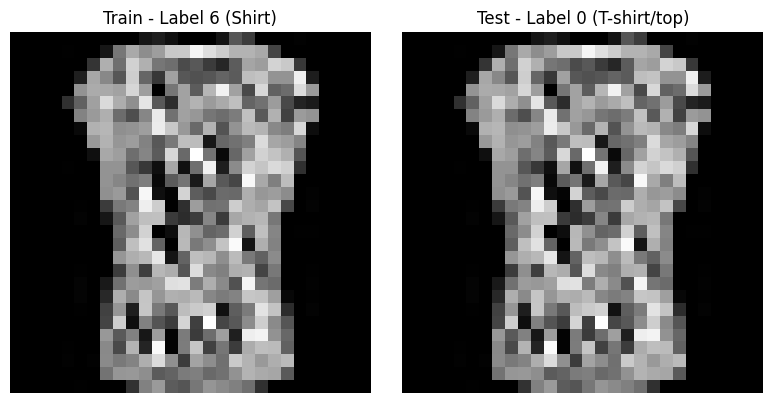


Verifikasi selesai. Dataset asli tidak diubah.


In [10]:

# ============================================================
# VERIFIKASI GAMBAR IDENTIK DENGAN LABEL BERBEDA
# Train: indeks 52205, label 6 (Shirt)
# Test : indeks 9560, label 0 (T-shirt/top)
# ============================================================

# Posisi baris berdasarkan hasil audit
train_index = 52205
test_index = 9560

# Mengambil data berdasarkan posisi baris
train_sample = train_df.iloc[train_index]
test_sample = test_df.iloc[test_index]

# Mengambil 784 nilai piksel dari masing-masing gambar
train_image_pixels = train_sample[
    train_pixel_columns
].to_numpy()

test_image_pixels = test_sample[
    test_pixel_columns
].to_numpy()

# Memastikan kedua gambar memiliki jumlah fitur yang sama
print("JUMLAH FITUR PIKSEL")
print("Train:", len(train_image_pixels))
print("Test :", len(test_image_pixels))

# Membandingkan seluruh 784 nilai piksel
pixels_identical = np.array_equal(
    train_image_pixels,
    test_image_pixels
)

# Menghitung jumlah piksel yang berbeda
different_pixel_count = np.count_nonzero(
    train_image_pixels != test_image_pixels
)

# Mengambil label asli
train_label = train_sample["label"]
test_label = test_sample["label"]

print("\nINFORMASI GAMBAR")
print("Indeks train:", train_index)
print("Label train :", train_label, "- Shirt")
print("Indeks test :", test_index)
print("Label test  :", test_label, "- T-shirt/top")

print("\nHASIL PERBANDINGAN")
print("Apakah 784 nilai piksel identik?:", pixels_identical)
print("Jumlah piksel yang berbeda       :", different_pixel_count)

# Memastikan kesesuaian hasil dengan temuan audit
assert len(train_image_pixels) == 784
assert len(test_image_pixels) == 784

# Visualisasi kedua gambar
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(
    train_image_pixels.reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[0].set_title(
    f"Train - Label {train_label} (Shirt)"
)
axes[0].axis("off")

axes[1].imshow(
    test_image_pixels.reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title(
    f"Test - Label {test_label} (T-shirt/top)"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("\nVerifikasi selesai. Dataset asli tidak diubah.")



### 8.2 Verifikasi Gambar Identik dengan Label Berbeda

Berdasarkan hasil audit lintas dataset, ditemukan satu kelompok gambar identik yang memiliki label berbeda antara data train dan test.

Verifikasi dilakukan dengan membandingkan seluruh 784 nilai piksel dari kedua gambar secara langsung.

Hasil pemeriksaan:

| Keterangan | Data Train | Data Test |
|---|---|---|
| Indeks baris | 52205 | 9560 |
| Label | 6 (Shirt) | 0 (T-shirt/top) |
| Jumlah fitur piksel | 784 | 784 |

Hasil perbandingan menunjukkan bahwa kedua gambar memiliki nilai piksel yang identik (`True`), dengan jumlah piksel berbeda sebanyak 0.

Temuan ini menunjukkan adanya inkonsistensi label pada gambar yang sama. Selain itu, keberadaan gambar identik pada data train dan test merupakan potensi data leakage yang perlu dipertimbangkan dalam evaluasi model.

Pada tahap eksplorasi ini, tidak dilakukan penghapusan gambar maupun perubahan label. Temuan dicatat sebagai bahan evaluasi dan pertimbangan kelompok sebelum menentukan kebijakan penanganan data.

## 9. Distribusi Label

Distribusi label menunjukkan jumlah sampel pada setiap kelas.

Pemeriksaan dilakukan untuk mengetahui apakah jumlah sampel
antar kelas relatif seimbang atau terdapat kelas dengan jumlah
sampel yang berbeda.

Hasil distribusi train dan test diperiksa secara terpisah.

In [11]:
# Memastikan kolom label tersedia sebelum menghitung distribusi

def find_label_column(df, dataset_name):
    matching_columns = [
        column for column in df.columns
        if str(column).strip().lower() == "label"
    ]

    if len(matching_columns) != 1:
        raise ValueError(
            f"Kolom label pada dataset {dataset_name} tidak ditemukan "
            "atau terdapat lebih dari satu kolom label.\n"
            f"Kolom yang tersedia: {df.columns.tolist()}"
        )

    return matching_columns[0]


train_label_col = find_label_column(train_df, "train")
test_label_col = find_label_column(test_df, "test")

print("Kolom label train:", train_label_col)
print("Kolom label test:", test_label_col)

# Menghitung jumlah sampel untuk setiap label
print("\nDISTRIBUSI LABEL TRAIN")
display(train_df[train_label_col].value_counts().sort_index())

print("\nDISTRIBUSI LABEL TEST")
display(test_df[test_label_col].value_counts().sort_index())

Kolom label train: label
Kolom label test: label

DISTRIBUSI LABEL TRAIN


label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


DISTRIBUSI LABEL TEST


label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64

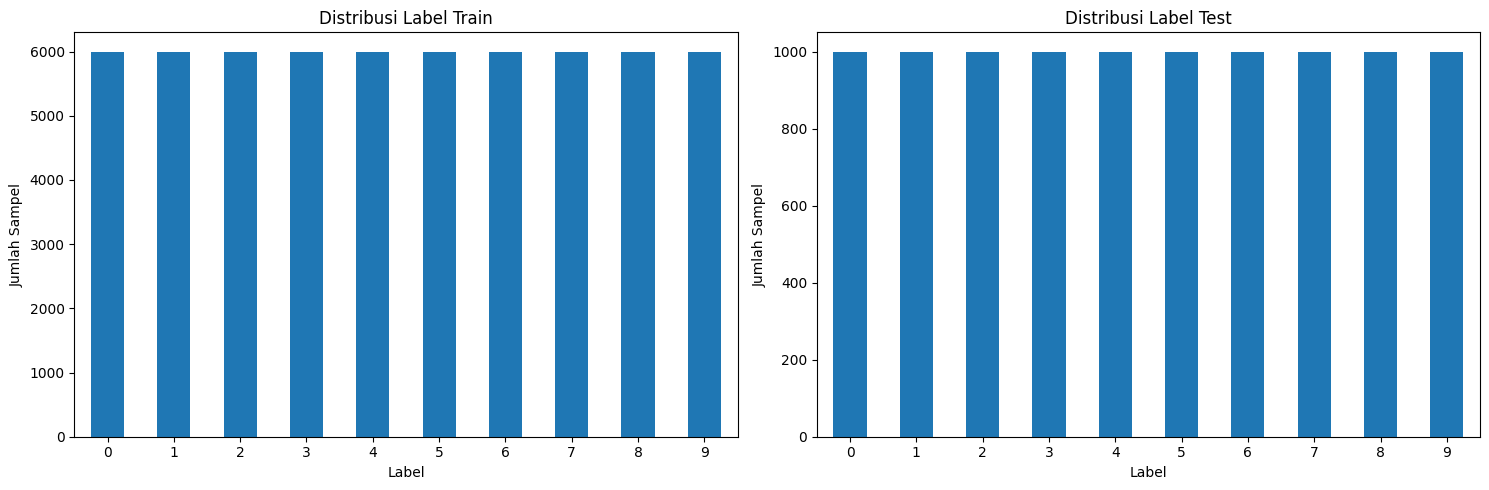

In [12]:
# Membuat visualisasi distribusi label

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

train_df[train_label_col].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Distribusi Label Train")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Jumlah Sampel")
axes[0].tick_params(axis="x", rotation=0)

test_df[test_label_col].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Distribusi Label Test")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Jumlah Sampel")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 10. Pemetaan Label Fashion-MNIST

Fashion-MNIST memiliki 10 kategori objek pakaian dan aksesori.

Setiap label numerik dipetakan ke nama kategori agar hasil
eksplorasi lebih mudah dipahami.

Pemetaan ini digunakan untuk membaca label dan visualisasi,
bukan untuk mengubah label asli pada CSV.

In [13]:
# Pemetaan label Fashion-MNIST

class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# Menampilkan tabel pemetaan
class_mapping_df = pd.DataFrame({
    "Label": list(class_names.keys()),
    "Nama Kategori": list(class_names.values())
})

display(class_mapping_df)

,Label,Nama Kategori
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


In [14]:
# Menampilkan distribusi label beserta nama kategorinya

def show_label_mapping(df, label_column, dataset_name):
    label_counts = (
        df[label_column]
        .value_counts()
        .sort_index()
        .rename_axis("Label")
        .reset_index(name="Jumlah Sampel")
    )

    label_counts["Nama Kategori"] = label_counts["Label"].map(class_names)

    print(f"DISTRIBUSI LABEL {dataset_name.upper()}")
    display(label_counts)

    unknown_labels = sorted(
        set(df[label_column].dropna().unique()) - set(class_names.keys())
    )

    if unknown_labels:
        print("Peringatan: ditemukan label di luar pemetaan:", unknown_labels)


show_label_mapping(train_df, train_label_col, "train")
show_label_mapping(test_df, test_label_col, "test")

DISTRIBUSI LABEL TRAIN


,Label,Jumlah Sampel,Nama Kategori
0,0,6000,T-shirt/top
1,1,6000,Trouser
2,2,6000,Pullover
3,3,6000,Dress
4,4,6000,Coat
5,5,6000,Sandal
6,6,6000,Shirt
7,7,6000,Sneaker
8,8,6000,Bag
9,9,6000,Ankle boot


DISTRIBUSI LABEL TEST


,Label,Jumlah Sampel,Nama Kategori
0,0,1000,T-shirt/top
1,1,1000,Trouser
2,2,1000,Pullover
3,3,1000,Dress
4,4,1000,Coat
5,5,1000,Sandal
6,6,1000,Shirt
7,7,1000,Sneaker
8,8,1000,Bag
9,9,1000,Ankle boot


## 11. Statistik Nilai Piksel

Setiap gambar Fashion-MNIST memiliki nilai piksel yang merepresentasikan
intensitas warna grayscale.

Pemeriksaan dilakukan untuk mengetahui:
- Nilai piksel minimum.
- Nilai piksel maksimum.
- Nilai rata-rata piksel.

Statistik dihitung dari seluruh kolom fitur piksel.

In [15]:
# Mengidentifikasi kolom piksel dari seluruh kolom selain label

train_pixel_columns = [
    column for column in train_df.columns
    if column != train_label_col
]

test_pixel_columns = [
    column for column in test_df.columns
    if column != test_label_col
]

# Memeriksa apakah seluruh kolom piksel dapat dibaca sebagai numerik
try:
    train_pixels_numeric = train_df[train_pixel_columns].apply(
        pd.to_numeric,
        errors="raise"
    )

    test_pixels_numeric = test_df[test_pixel_columns].apply(
        pd.to_numeric,
        errors="raise"
    )

except (ValueError, TypeError) as error:
    raise ValueError(
        "Ditemukan kolom fitur piksel yang berisi nilai non-numerik. "
        "Periksa struktur CSV terlebih dahulu."
    ) from error

# Statistik piksel
train_pixel_stats = {
    "Minimum": train_pixels_numeric.min().min(),
    "Maksimum": train_pixels_numeric.max().max(),
    "Rata-rata": train_pixels_numeric.mean().mean()
}

test_pixel_stats = {
    "Minimum": test_pixels_numeric.min().min(),
    "Maksimum": test_pixels_numeric.max().max(),
    "Rata-rata": test_pixels_numeric.mean().mean()
}

print("STATISTIK NILAI PIKSEL TRAIN")
display(pd.Series(train_pixel_stats, name="Nilai"))

print("\nSTATISTIK NILAI PIKSEL TEST")
display(pd.Series(test_pixel_stats, name="Nilai"))

STATISTIK NILAI PIKSEL TRAIN


Minimum        0.000000
Maksimum     255.000000
Rata-rata     72.956831
Name: Nilai, dtype: float64


STATISTIK NILAI PIKSEL TEST


Minimum        0.000000
Maksimum     255.000000
Rata-rata     73.160805
Name: Nilai, dtype: float64

## 12. Validasi Jumlah Fitur Piksel

Gambar Fashion-MNIST diharapkan memiliki ukuran 28 × 28 piksel
dengan satu channel grayscale.

Dengan demikian, setiap gambar membutuhkan:

28 × 28 = 784 fitur piksel.

Pada bagian ini, jumlah kolom selain label diperiksa untuk
memastikan kesesuaiannya dengan ukuran gambar yang diharapkan.

Jika jumlah fitur tidak sesuai, notebook akan menghentikan proses
dengan pesan yang menjelaskan struktur yang ditemukan.

In [16]:
# Memeriksa jumlah fitur piksel

expected_pixel_count = 28 * 28

train_pixel_count = len(train_pixel_columns)
test_pixel_count = len(test_pixel_columns)

print("Jumlah fitur piksel train:", train_pixel_count)
print("Jumlah fitur piksel test:", test_pixel_count)
print("Jumlah fitur yang diharapkan:", expected_pixel_count)

if train_pixel_count != expected_pixel_count:
    raise ValueError(
        f"Jumlah fitur piksel train tidak sesuai. "
        f"Ditemukan {train_pixel_count}, seharusnya {expected_pixel_count}."
    )

if test_pixel_count != expected_pixel_count:
    raise ValueError(
        f"Jumlah fitur piksel test tidak sesuai. "
        f"Ditemukan {test_pixel_count}, seharusnya {expected_pixel_count}."
    )

print("\nValidasi jumlah fitur piksel berhasil.")

Jumlah fitur piksel train: 784
Jumlah fitur piksel test: 784
Jumlah fitur yang diharapkan: 784

Validasi jumlah fitur piksel berhasil.


## 13. Representasi Data Menjadi Gambar

Setiap baris data memiliki 784 nilai piksel.

Nilai tersebut disusun kembali menjadi matriks berukuran 28 × 28
menggunakan NumPy.

Matriks kemudian dapat ditampilkan sebagai gambar grayscale.

Pada bagian ini tidak dilakukan normalisasi atau perubahan nilai piksel.

Bentuk gambar: (28, 28)
Tipe data gambar: float32


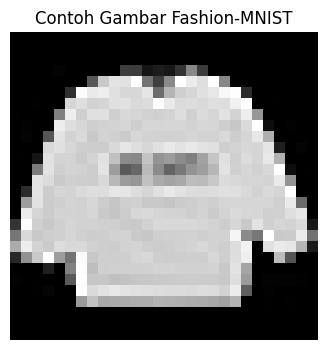

In [17]:
# Fungsi untuk merepresentasikan satu baris CSV menjadi gambar

def row_to_image(row, pixel_columns):
    """
    Mengubah satu baris fitur piksel menjadi matriks gambar 28 x 28.
    """

    pixel_values = pd.to_numeric(
        row[pixel_columns],
        errors="raise"
    ).to_numpy(dtype=np.float32)

    if len(pixel_values) != 784:
        raise ValueError(
            f"Jumlah piksel harus 784, tetapi ditemukan {len(pixel_values)}."
        )

    image = pixel_values.reshape(28, 28)

    return image


# Mengambil satu sampel dari train
sample_index = 0

sample_image = row_to_image(
    train_df.iloc[sample_index],
    train_pixel_columns
)

print("Bentuk gambar:", sample_image.shape)
print("Tipe data gambar:", sample_image.dtype)

plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title("Contoh Gambar Fashion-MNIST")
plt.axis("off")
plt.show()

## 14. Visualisasi Sampel Gambar

Bagian ini menampilkan beberapa sampel gambar dari dataset train.

Setiap gambar ditampilkan bersama label numerik dan nama kategorinya.

Visualisasi dilakukan untuk memastikan bahwa susunan 784 fitur
piksel dapat direpresentasikan sebagai gambar grayscale 28 × 28.

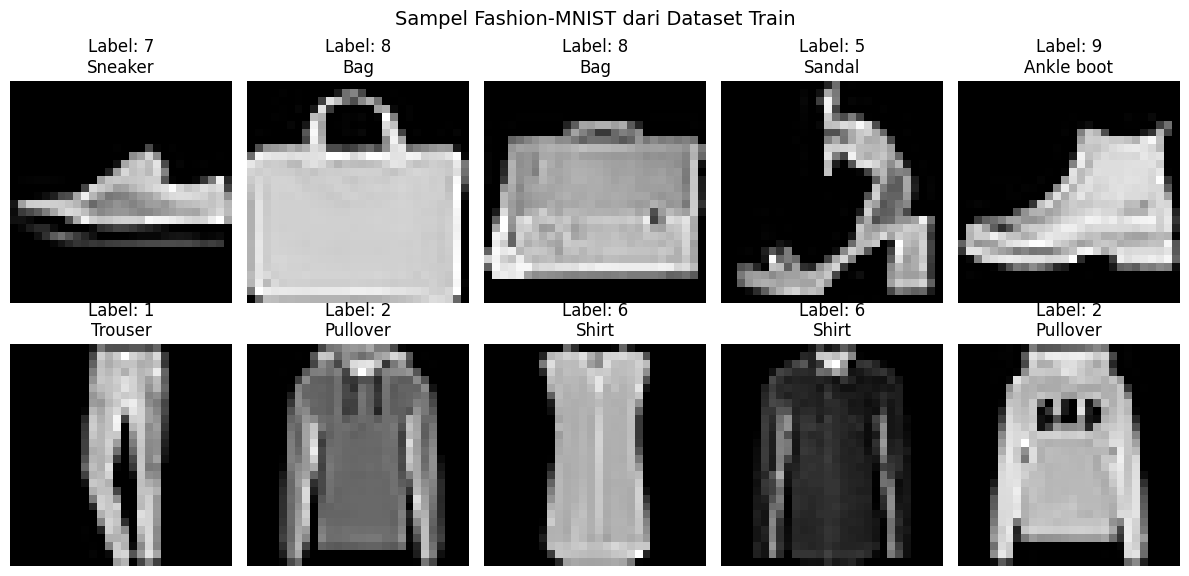

In [18]:
# Menampilkan beberapa sampel gambar dari dataset train

number_of_samples = min(10, len(train_df))

if number_of_samples == 0:
    raise ValueError("Dataset train tidak memiliki sampel untuk divisualisasikan.")

# Memilih sampel secara acak dengan random_state agar hasil dapat diulang
sample_indices = train_df.sample(
    n=number_of_samples,
    random_state=42
).index

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for ax, index in zip(axes, sample_indices):
    row = train_df.loc[index]

    image = row_to_image(
        row,
        train_pixel_columns
    )

    label = row[train_label_col]
    category = class_names.get(label, "Unknown")

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}\n{category}")
    ax.axis("off")

# Menyembunyikan subplot yang tidak digunakan
for ax in axes[number_of_samples:]:
    ax.axis("off")

plt.suptitle("Sampel Fashion-MNIST dari Dataset Train", fontsize=14)
plt.tight_layout()
plt.show()

In [19]:
# Memeriksa kesesuaian struktur kolom train dan test

train_columns = list(train_df.columns)
test_columns = list(test_df.columns)

if train_columns != test_columns:
    raise ValueError(
        "Struktur kolom train dan test tidak sama atau urutannya berbeda.\n"
        f"Kolom train: {train_columns}\n"
        f"Kolom test: {test_columns}"
    )

if train_label_col != test_label_col:
    raise ValueError(
        "Nama kolom label train dan test tidak konsisten."
    )

print("Struktur kolom train dan test konsisten.")

Struktur kolom train dan test konsisten.


In [21]:

# ============================================================
# RINGKASAN HASIL EKSPLORASI DATASET FASHION-MNIST
# ============================================================

print("=" * 60)
print("RINGKASAN DATASET EXPLORATION FASHION-MNIST")
print("=" * 60)

print("\n1. DIMENSI DATASET")
print(f"Train : {train_df.shape[0]} baris, {train_df.shape[1]} kolom")
print(f"Test  : {test_df.shape[0]} baris, {test_df.shape[1]} kolom")

print("\n2. STRUKTUR DATA")
print(f"Kolom label        : {train_label_col}")
print(f"Fitur piksel train : {len(train_pixel_columns)}")
print(f"Fitur piksel test  : {len(test_pixel_columns)}")

print("\n3. KUALITAS DATA")
print(f"Missing values train : {train_missing.sum()}")
print(f"Missing values test  : {test_missing.sum()}")
print(f"Duplikat baris train : {train_duplicates}")
print(f"Duplikat baris test  : {test_duplicates}")

print("\n4. AUDIT DUPLIKASI GAMBAR")
print("Kelompok gambar identik dalam train:",
      len(train_duplicate_images))
print("Kelompok gambar identik dalam test:",
      len(test_duplicate_images))
print("Kelompok gambar identik lintas train-test:",
      len(cross_split_duplicates))

print("Konflik label dalam train:",
      train_conflicts)
print("Konflik label dalam test:",
      test_conflicts)
print("Konflik label lintas train-test:",
      cross_conflicts)

print("\n5. STATISTIK NILAI PIKSEL")
print(f"Train minimum  : {train_pixel_stats['Minimum']}")
print(f"Train maksimum : {train_pixel_stats['Maksimum']}")
print(f"Train rata-rata: {train_pixel_stats['Rata-rata']:.4f}")
print(f"Test minimum   : {test_pixel_stats['Minimum']}")
print(f"Test maksimum  : {test_pixel_stats['Maksimum']}")
print(f"Test rata-rata : {test_pixel_stats['Rata-rata']:.4f}")

print("\n6. DISTRIBUSI LABEL TRAIN")
display(
    train_df[train_label_col]
    .value_counts()
    .sort_index()
    .rename("Jumlah Sampel")
)

print("\n7. DISTRIBUSI LABEL TEST")
display(
    test_df[test_label_col]
    .value_counts()
    .sort_index()
    .rename("Jumlah Sampel")
)

print("\n8. VALIDASI UKURAN GAMBAR")
print("Fitur piksel train sesuai 28 x 28:",
      len(train_pixel_columns) == 784)
print("Fitur piksel test sesuai 28 x 28:",
      len(test_pixel_columns) == 784)

print("\nEksplorasi selesai. Dataset asli tidak diubah.")
print("Seluruh temuan perlu ditinjau sebelum preprocessing.")


RINGKASAN DATASET EXPLORATION FASHION-MNIST

1. DIMENSI DATASET
Train : 60000 baris, 785 kolom
Test  : 10000 baris, 785 kolom

2. STRUKTUR DATA
Kolom label        : label
Fitur piksel train : 784
Fitur piksel test  : 784

3. KUALITAS DATA
Missing values train : 0
Missing values test  : 0
Duplikat baris train : 43
Duplikat baris test  : 1

4. AUDIT DUPLIKASI GAMBAR
Kelompok gambar identik dalam train: 43
Kelompok gambar identik dalam test: 1
Kelompok gambar identik lintas train-test: 10
Konflik label dalam train: 0
Konflik label dalam test: 0
Konflik label lintas train-test: 1

5. STATISTIK NILAI PIKSEL
Train minimum  : 0
Train maksimum : 255
Train rata-rata: 72.9568
Test minimum   : 0
Test maksimum  : 255
Test rata-rata : 73.1608

6. DISTRIBUSI LABEL TRAIN


label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: Jumlah Sampel, dtype: int64


7. DISTRIBUSI LABEL TEST


label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: Jumlah Sampel, dtype: int64


8. VALIDASI UKURAN GAMBAR
Fitur piksel train sesuai 28 x 28: True
Fitur piksel test sesuai 28 x 28: True

Eksplorasi selesai. Dataset asli tidak diubah.
Seluruh temuan perlu ditinjau sebelum preprocessing.


## 15. Kesimpulan Dataset Exploration

Berdasarkan hasil eksplorasi dataset Fashion-MNIST, diperoleh kesimpulan sebagai berikut.

### 15.1 Karakteristik Dataset

Dataset Fashion-MNIST terdiri dari 60.000 sampel data train dan 10.000 sampel data test. Masing-masing dataset memiliki 785 kolom, yang terdiri dari satu kolom `label` dan 784 fitur piksel.

Seluruh kolom memiliki tipe data integer (`int64`), dan tidak ditemukan missing values pada kedua dataset.

### 15.2 Distribusi Kelas

Dataset memiliki 10 kategori pakaian dan aksesori dengan distribusi kelas yang seimbang.

Setiap kelas memiliki 6.000 sampel pada data train dan 1.000 sampel pada data test.

### 15.3 Statistik Nilai Piksel

Nilai piksel pada kedua dataset berada dalam rentang 0–255.

Rata-rata nilai piksel pada data train adalah 72,9568, sedangkan pada data test adalah 73,1608.

Jumlah fitur piksel telah sesuai dengan ukuran gambar Fashion-MNIST, yaitu 28 × 28 piksel dengan satu channel grayscale.

### 15.4 Hasil Audit Duplikasi

Pemeriksaan duplikasi berdasarkan seluruh isi baris menemukan 43 baris duplikat pada data train dan 1 baris duplikat pada data test.

Audit lanjutan berdasarkan 784 fitur piksel menemukan:

- 43 kelompok gambar identik dalam data train.
- 1 kelompok gambar identik dalam data test.
- 10 kelompok gambar identik yang muncul pada data train dan test.
- Tidak ditemukan konflik label pada kelompok gambar identik di dalam train maupun di dalam test.
- Ditemukan 1 kelompok gambar identik lintas dataset yang memiliki label berbeda.

Konflik label tersebut ditemukan pada indeks train 52205 dengan label 6 (*Shirt*) dan indeks test 9560 dengan label 0 (*T-shirt/top*).

Verifikasi langsung menunjukkan bahwa seluruh 784 nilai piksel kedua gambar identik, dengan jumlah piksel berbeda sebanyak 0.

Temuan tersebut menunjukkan inkonsistensi label pada gambar identik. Selain itu, keberadaan gambar yang sama dalam data train dan test menimbulkan potensi kebocoran informasi antarpembagian data (*data leakage*) yang dapat memengaruhi validitas evaluasi model.

### 15.5 Kesiapan Dataset untuk Tahap Selanjutnya

Hasil eksplorasi menunjukkan bahwa struktur dataset sesuai dengan kebutuhan awal pengembangan Vision Transformer (ViT) Minimalis.

Namun, temuan duplikasi dan inkonsistensi label perlu dipertimbangkan sebelum menentukan strategi preprocessing dan evaluasi model.

Pada tahap Dataset Exploration ini, tidak dilakukan penghapusan data, perubahan label, normalisasi, maupun modifikasi dataset asli.

Keputusan mengenai penanganan duplikasi, konflik label, dan potensi data leakage akan dibahas serta disetujui oleh kelompok sebelum implementasi tahap selanjutnya.

Dengan demikian, pemeriksaan utama Dataset Exploration telah diselesaikan, sedangkan kebijakan penanganan temuan kualitas data masih memerlukan keputusan kelompok.